# Калибровка датчика давления с помощью реперных точек

Цель: по известным давлениям фазовых переходов в нескольких материалах (реперным точкам) определить функцию преобразования выходного напряжения 
тензодатчика (мВ) в истинное давление (Па).

Исходные данные: для каждого материала записаны временные ряды сопротивления образца при ступенчатом изменении давления. 
Файлы получены с измерительной установки в формате `.xls`.

## Структура исходных данных:

Каждый файл содержит колонки:

* `Time` - время, показывающее момент получания значения сопротивления,

* `OHM` - сопротивление образца, в Ом

* колонка со значением давления, в В (заполнена только первая ячейка для группы значений сопротивления, измеренных при одном давлении),

* колонка, указывающая цикл измерений (заполнена не во всех файлах)

* технические столбцы.

Пример данных:

In [1]:
import xlrd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scripts.data_processing import inp, fill_press, avg_last, save

file_name = 'NaCl.xls'

book = xlrd.open_workbook(Path('data/raw') / file_name)
sheet = book.sheet_by_index(0)

data = []
for row in range(sheet.nrows):
    data.append(sheet.row_values(row))


df = pd.DataFrame(data[1:], columns=data[0])

df.head()

,Time,OHM,,,Start Time,46209.71015
0,46209.710162,47058067.2,0.3,1up,Interval,0.000058
1,46209.710509,47735324.8,,,,
2,46209.710567,44720105.6,,,Samples Completed,2185.0
3,46209.710625,45964300.8,,,,
4,46209.710683,42427043.2,,,Last Point on Chart,2185.0


In [2]:
df.iloc[3602:3609]

,Time,OHM,,,Start Time,46209.71015
3602,46210.558796,12754.5312,,,,
3603,46210.558854,12742.2240,,,,
3604,46210.559201,12765.9592,,,,
3605,46210.559259,12871.4856,3.6,2down,,
3606,46210.559317,12878.4904,,,,
3607,46210.559375,12867.2024,,,,
3608,46210.559433,12870.0208,,,,


колонка `Time` читается неправильно, она, а так же техническая информация из 4 и 5 колонок не нужны для дальнейшей обработки

## Обработка данных

Обработка всех файлов с зависимостями сопротивления от давления производится с помощью цикла, который:

читает файл в формате .xls
заполняет пропущенные значения давления
усредняет последние 25 значений сопротивления
сохраняет результат в файл excel

In [3]:
materials = {
    'ZnS': 'ZnS.xls',
    'CdS': 'CdS.xls',
    'KBr': 'KBr.xls',
    'NaCl': 'NaCl.xls',
    'Bi2Te3': 'Bi2Te3.xls',
    'dwcnt': 'dwcnt.xls'
}

fill_direction = 'up' #заполнена только первая ячейка для группы значений сопротивления
#fill_direction = 'dn' #заполнена только последняя ячейка для группы значений сопротивления

processed = {}

for name, file_name in materials.items():
    df = inp(file_name) #чтение файла, остаются только необходимые значения
    df = fill_press(df, fill_direction) #обработка пропусков
    df = avg_last(df) #усреднение значений
    processed[name] = df
    save(df, file_name) #сохраняем результат

## Построение графиков

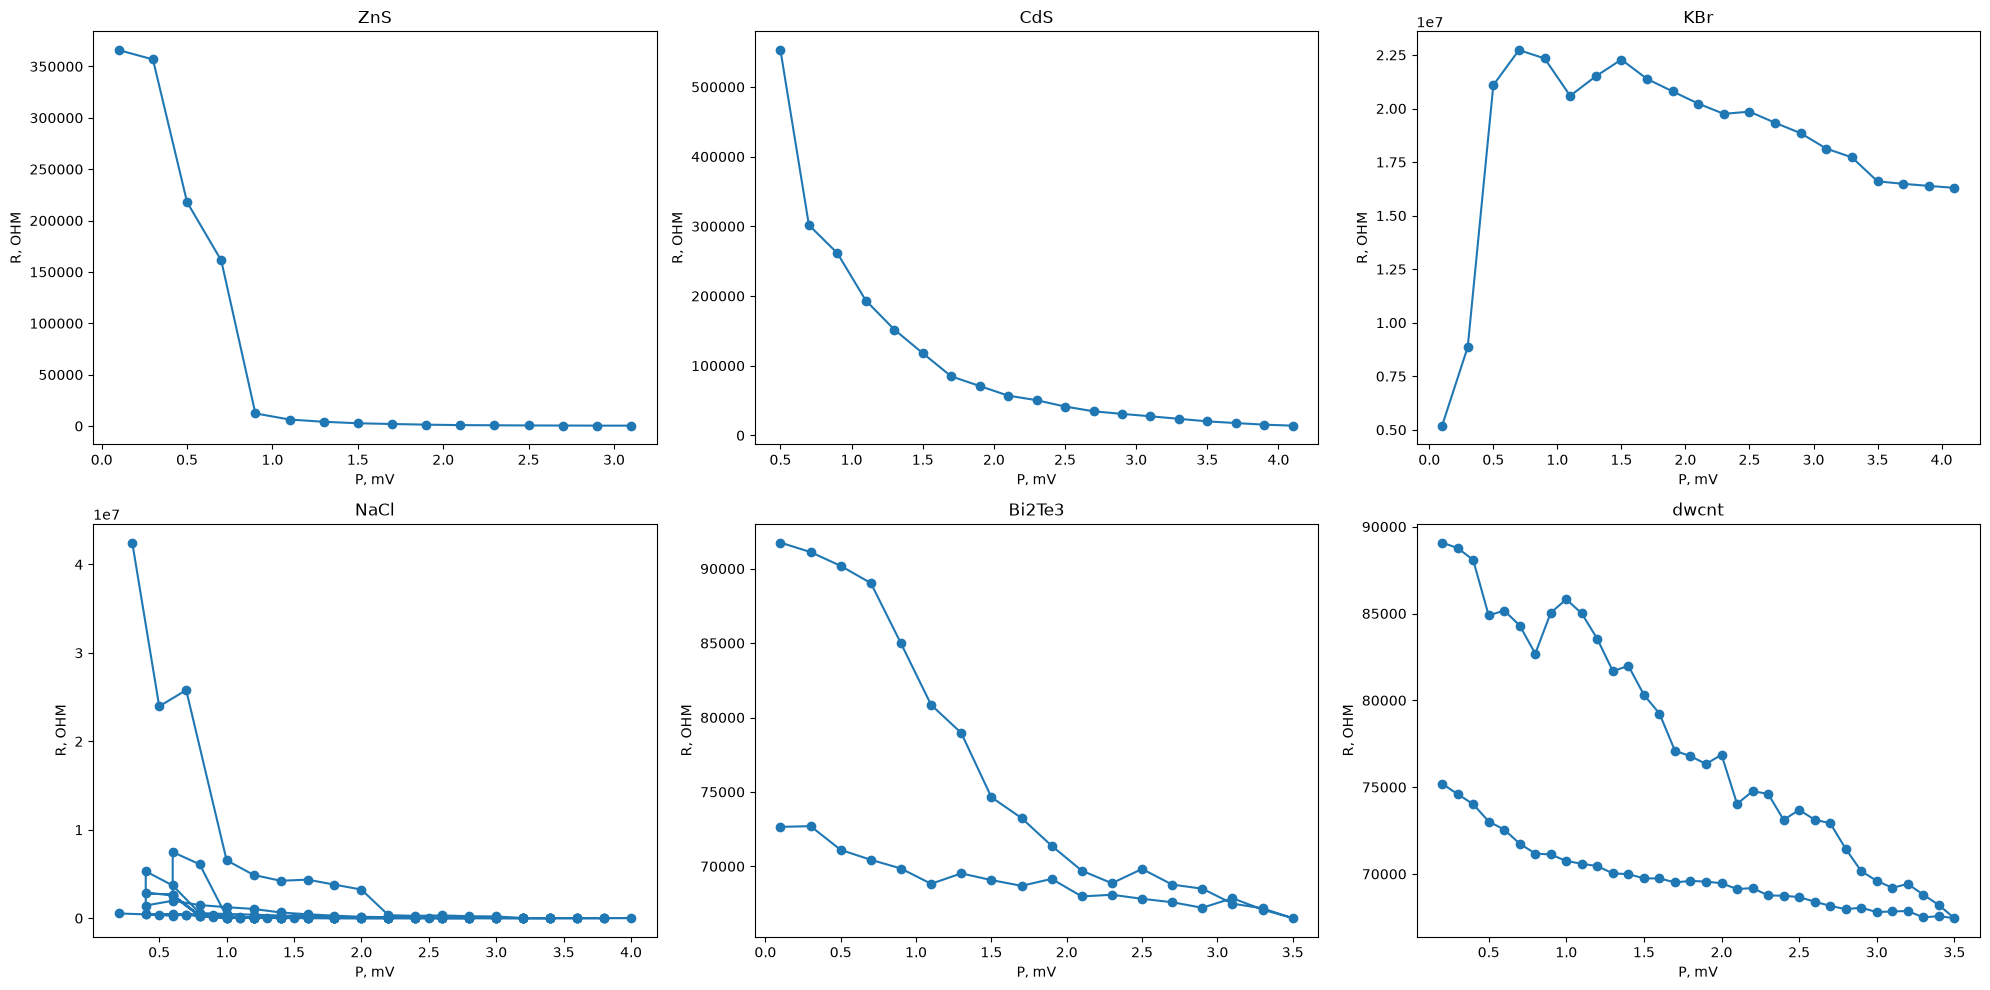

In [17]:
fig, ax= plt.subplots(nrows=2, ncols=3, figsize=(20, 10))


ax[0,0].plot(processed['ZnS']['P, mV'], processed['ZnS']['R, OHM'], marker='o')
ax[0,0].set_xlabel('P, mV')
ax[0,0].set_ylabel('R, OHM')
ax[0,0].set_title('ZnS')

ax[0,1].plot(processed['CdS']['P, mV'], processed['CdS']['R, OHM'], marker='o')
ax[0,1].set_xlabel('P, mV')
ax[0,1].set_ylabel('R, OHM')
ax[0,1].set_title('CdS')

ax[0,2].plot(processed['KBr']['P, mV'], processed['KBr']['R, OHM'], marker='o')
ax[0,2].set_xlabel('P, mV')
ax[0,2].set_ylabel('R, OHM')
ax[0,2].set_title('KBr')

ax[1,0].plot(processed['NaCl']['P, mV'], processed['NaCl']['R, OHM'], marker='o')
ax[1,0].set_xlabel('P, mV')
ax[1,0].set_ylabel('R, OHM')
ax[1,0].set_title('NaCl')

ax[1,1].plot(processed['Bi2Te3']['P, mV'], processed['Bi2Te3']['R, OHM'], marker='o')
ax[1,1].set_xlabel('P, mV')
ax[1,1].set_ylabel('R, OHM')
ax[1,1].set_title('Bi2Te3')

ax[1,2].plot(processed['dwcnt']['P, mV'], processed['dwcnt']['R, OHM'], marker='o')
ax[1,2].set_xlabel('P, mV')
ax[1,2].set_ylabel('R, OHM')
ax[1,2].set_title('dwcnt')

#graph_file = f"graph_averaged.png" #можно сохранить полученные графики
#plt.savefig(graph_file)

plt.tight_layout()
plt.show()

Данные графики показывают резкое изменение сопротивления с изменением дваления.

Для веществ ZnS, CdS, KBr измерения проводились только при уменьшении давления. Для Bi2Te3 и нанотрубок (6 график) давление сначала увеличивалось, а потом уменьшалось, а для NaCl было измеренно 5 таких циклов.

### Обработка циклов NaCl

Построим отдельно графика для каждого цикла NaCl

In [5]:
nacl = processed['NaCl']

nacl['num'] = nacl['series'].str.extract(r'(\d+)').astype(float)
nacl['num'] = nacl['num'].ffill()

nacl.head()

,"P, mV","R, OHM",series,num
0,0.3,4.247040e+07,1up,1.0
1,0.5,2.395705e+07,,1.0
2,0.7,2.579372e+07,,1.0
3,1.0,6.549162e+06,,1.0
4,1.2,4.894861e+06,,1.0


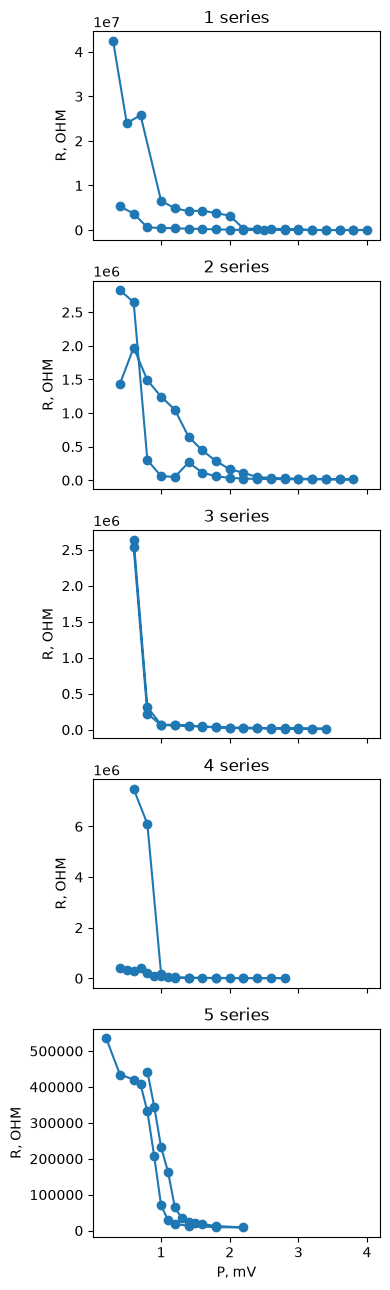

In [16]:
fig, ax = plt.subplots(nrows=5, ncols=1, figsize=(4, 13), sharex=True)

for i, (cycle_num, group) in enumerate(nacl.groupby('num')):
    ax[i].plot(group['P, mV'], group['R, OHM'], marker='o')
    ax[i].set_ylabel('R, OHM')
    ax[i].set_title(f'{i + 1} series')

ax[-1].set_xlabel('P, mV')

plt.tight_layout()
plt.show()

Видно, что переход в циклах происходит примерно при одном и том же давлении

### Очистка данных от выбросов для KBr

На графике KBr можно заметить, что первые две точки являются выбросами (вероятно, они связанны с неплотным прилеганием контакотов прибора
в начале измерения), удалим эти точки, что бы не искажать масштаб.

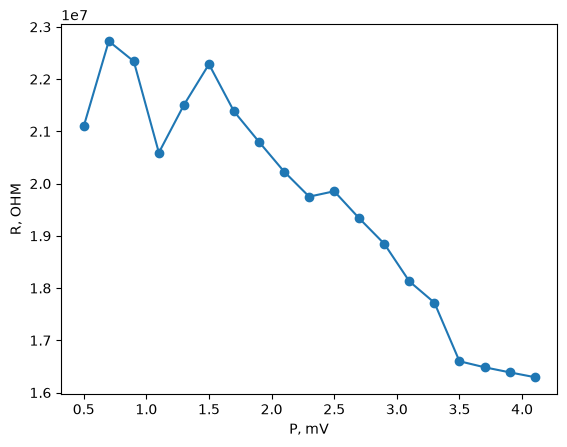

In [19]:
kbr = processed['KBr']

kbr = kbr.iloc[2:].reset_index(drop=True)

fig, ax = plt.subplots()
ax.plot(kbr['P, mV'], kbr['R, OHM'], marker = 'o')
ax.set_xlabel('P, mV')
ax.set_ylabel('R, OHM')

plt.show()